# 3. The period search

A transit repeats. The Box Least Squares (BLS) search folds the light curve at each
trial period and asks how well a box-shaped dip fits. The tool `bls_peaks` returns
the strongest distinct peaks. The tool `search_signals` runs the search, masks the
strongest signal, and searches again until the rest is noise. This notebook shows
both on the loaded episode.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("..").resolve()))
sys.path.insert(0, str(Path("../tests").resolve()))
plt.rcParams["figure.figsize"] = (11, 3.5)
plt.rcParams["figure.dpi"] = 110

EPISODES = Path("../data/episodes/s98_v2")


def load_episode(episode_id="ep_0001"):
    """Return (time, flux, truth) for one real episode, or a synthetic one if the set is absent."""
    if EPISODES.exists():
        from stargazer.episodes import EpisodeSet

        episode_set = EpisodeSet(EPISODES)
        time, flux, _ = episode_set.load(episode_id)
        return time, flux, episode_set.truth[episode_id]
    from conftest import synthetic_lc

    from stargazer.inject import inject, make_truth

    time, flux, _ = synthetic_lc(days=57.0)
    time = time - time.min()
    star = {"teff": 5500.0, "logg": 4.45, "radius_rsun": 0.95, "tmag": 10.0, "mass_msun": 0.95}
    truth = make_truth(period=0.7764, t0=0.1453, depth=0.0016, b=0.3, star=star)
    transit = {"period": truth.period, "t0": truth.t0, "duration": truth.duration, "depth": truth.depth}
    record = {"kind": "transit", "n_transits": 73, "snr": 60.0, "transit": transit}
    return time, inject(time, flux, truth), record


time, flux, truth = load_episode()
print(f"{len(time)} points over {time.max() - time.min():.1f} days; truth kind {truth['kind']}")

26521 points over 57.4 days; truth kind transit


## Detrending first

Both tools detrend the light curve before the search: a Savitzky-Golay filter fits a
polynomial in a sliding window and divides the flux by the fit. The window must be
several times the transit duration or the filter erases the dip. The plot shows the
raw and the detrended flux.

/home/siddharth899/personal_code/star_finder/.venv/lib/python3.13/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


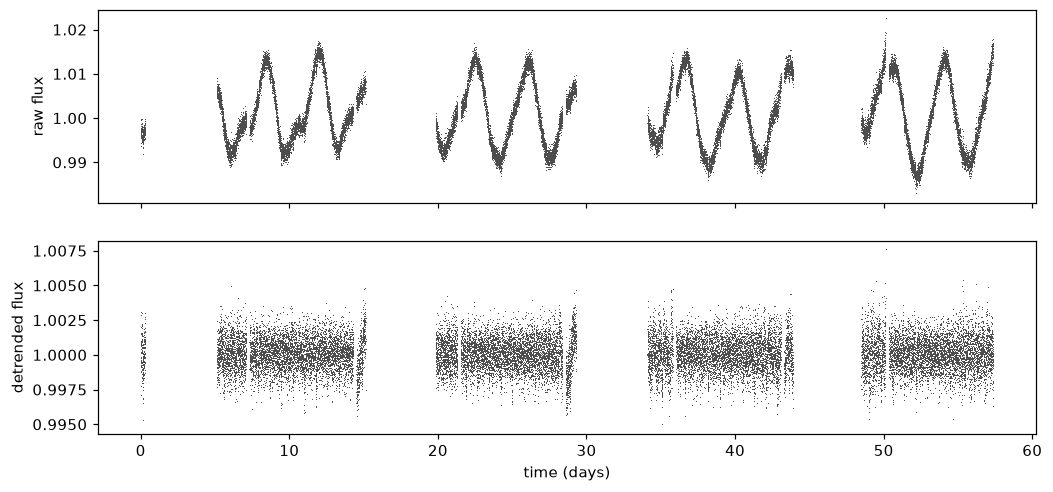

In [2]:
from stargazer.baseline import detrend

flat_time, flat_flux = detrend(time, flux, 0.75)
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(11, 5))
top.plot(time, flux, ",", color="0.3")
top.set_ylabel("raw flux")
bottom.plot(flat_time, flat_flux, ",", color="0.3")
bottom.set_ylabel("detrended flux")
bottom.set_xlabel("time (days)")
plt.show()

## `bls_peaks`

Each peak has a period, an epoch, a duration, a depth and a signal detection
efficiency (SDE): how far the peak stands above the mean of the periodogram, in
standard deviations. On real stars noise alone reaches an SDE of 10 to 14, so a peak
is a hypothesis to check, not a result. The tool also returns the half and double
period of each peak, because a search often lands on an alias of the true period.

In [3]:
from stargazer.tools import bls_peaks

peaks = bls_peaks(time, flux)
for peak in peaks["peaks"]:
    print({key: peak[key] for key in ("period", "t0", "duration", "depth_ppm", "sde", "n_events_in_data")})

{'period': 0.77639, 't0': 0.1453, 'duration': 0.051, 'depth_ppm': 1354.9, 'sde': 23.6, 'n_events_in_data': 74}
{'period': 1.55275, 't0': 0.9223, 'duration': 0.051, 'depth_ppm': 1388.2, 'sde': 12.0, 'n_events_in_data': 37}
{'period': 2.32912, 't0': 0.9223, 'duration': 0.051, 'depth_ppm': 1398.6, 'sde': 7.88, 'n_events_in_data': 25}
{'period': 3.10557, 't0': 0.9223, 'duration': 0.051, 'depth_ppm': 1502.8, 'sde': 6.09, 'n_events_in_data': 19}
{'period': 0.51756, 't0': 0.4063, 'duration': 0.051, 'depth_ppm': 551.1, 'sde': 5.28, 'n_events_in_data': 111}


## `search_signals`

A strong signal dominates the periodogram at every period. The multiple-planet
search of the mission pipelines removes each signal it accepts and searches again.
The tool returns the signals in order and the SDE of the strongest peak left, so
the reader can see where the search stopped.

In [4]:
from stargazer.tools import search_signals

found = search_signals(time, flux)
for signal in found["signals"]:
    print({key: signal[key] for key in ("rank", "period", "t0", "depth_ppm", "sde")})
print("residual sde", found["residual_sde"], "stop", found["stop"])

{'rank': 1, 'period': 0.77639, 't0': 0.1453, 'depth_ppm': 1354.9, 'sde': 23.6}
residual sde 8.95 stop below_min_sde


## The fold

A fold places every point at its phase in the orbit of the top signal. A planet
shows one dip at phase 0 and a flat curve elsewhere. The plot folds at the first
signal's period and epoch, binned to 10 minutes, with the truth's period in the
title for comparison.

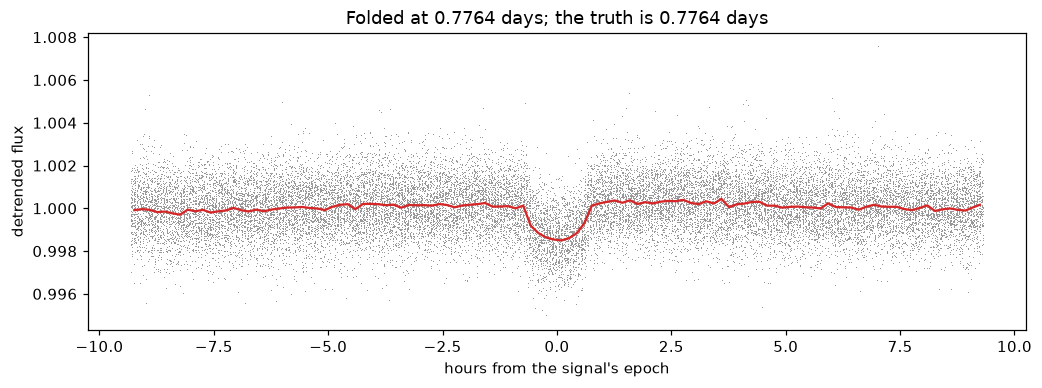

In [5]:
from stargazer.baseline import bin_lc

top = found["signals"][0] if found["signals"] else peaks["peaks"][0]
phase = ((flat_time - top["t0"] + 0.5 * top["period"]) % top["period"]) - 0.5 * top["period"]
order = np.argsort(phase)
bin_phase, bin_flux, _ = bin_lc(phase[order] + 0.5 * top["period"], flat_flux[order], 10.0)
fig, axis = plt.subplots()
axis.plot(phase * 24, flat_flux, ",", color="0.6")
axis.plot((bin_phase - 0.5 * top["period"]) * 24, bin_flux, "-", color="tab:red", lw=1.5)
axis.set_xlabel("hours from the signal's epoch")
axis.set_ylabel("detrended flux")
true_period = f"{truth['transit']['period']:.4f} days" if truth["kind"] == "transit" else "none"
axis.set_title(f"Folded at {top['period']:.4f} days; the truth is {true_period}")
plt.show()